# Milestone 2: Model Training and Comparison
**FEMA Individuals & Households Program (IHP) registrations, Hurricane Ian (DR-4673), Lee County, FL**

**Team FEMA:** Anthony Stoneking, Daniel Ortiz, Nandor Laar
**Course:** CAI 4105 Machine Learning, Fall 2026

## Project Overview
We want to predict whether a person who registered with FEMA after Hurricane Ian was **awarded aid** (`ihpEligible`).
This notebook covers the *Modeling* phase (CRISP-DM). We train ten different kinds of models from class, tune each one,
and compare them on the same data so we can pick the best one.

## Dataset Information
- **File:** `ihp_dr4673_lee.csv` (OpenFEMA *Individuals and Households Program - Valid Registrations* v2, filtered to Hurricane Ian and Lee County)
- **Content:** 194,482 registrations, one row per household that applied
- **Target Variable:** `ihpEligible` (1 = awarded aid, 0 = not awarded). The classes are almost even (about 51% / 49%).
- **Predictors:** two feature sets, called *tiers*, based on *when* the information is known:
  - **Tier 1 (application):** 25 features known the moment someone registers (age, household, income bracket, insurance, damage they reported, ZIP code, ...)
  - **Tier 2 (inspection):** the 25 Tier 1 features plus 14 more that FEMA only knows after an inspector visits (verified loss, flood level, ownership checks, ...)

## How to run
Put `ihp_dr4673_lee.csv` in the same folder as this notebook, then Kernel → *Restart & Run All*.
It needs only pandas, numpy, matplotlib, seaborn, and scikit-learn. A full run takes about 7 minutes on a laptop.
Every chart is also saved to a `figures/` folder next to the notebook.

## How this notebook is organized
1. **Setup and data preparation**: load the data, keep only the allowed features, and split it into training, validation, and test sets.
2. **Models 0 to 10**: for each model we explain what it is, why we tried it, and which settings we tuned. Then we run it on both tiers and explain the results.
3. **Model comparison**: all models side by side, and the model we pick.
4. **Final test**: the one-time score on the held-back test set.

> *AI-use disclosure:* the code and the first draft of the explanations in this notebook were written with Claude Code and then checked and revised by the team. See `docs/AI_USAGE.md` in the project repository.

---
# Part 1: Setup and Data Preparation

## Import Required Libraries

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay,
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC, SVC

# Some models print many "did not converge" / "collinear" warnings during the grid searches.
# They do not stop the code, so we hide them to keep the output readable.
warnings.filterwarnings("ignore")

RANDOM_STATE = 42   # same seed for every split and model, so every run gives the same numbers

## Chart style
The same colors as our EDA notebook: **blue** for Tier 1 results, **aqua** for Tier 2, gray for everything else.

In [2]:
BLUE = "#2a78d6"    # Tier 1 / main series
AQUA = "#1baf7a"    # Tier 2
ORANGE = "#eb6834"  # not eligible (confusion matrices)
GRAY = "#898781"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
TIER_COLORS = {"application": BLUE, "inspection": AQUA}
TIER_NAMES = {"application": "Tier 1 (application)", "inspection": "Tier 2 (inspection)"}
FIG_DIR = Path("figures")

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.edgecolor": GRID, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2,
})


def save_fig(name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIG_DIR / f"m2_model_{name}.png")

## Load the data
The file has 194,482 rows and 127 columns. Most of the columns are **not** allowed as model inputs (see the next step).

In [3]:
CSV_NAME = "ihp_dr4673_lee.csv"
CSV_CANDIDATES = [Path(CSV_NAME), Path("../../data/raw") / CSV_NAME, Path("data/raw") / CSV_NAME]


def load_data():
    for path in CSV_CANDIDATES:
        if path.exists():
            return pd.read_csv(path, low_memory=False)
    raise FileNotFoundError(f"Put {CSV_NAME} in the same folder as this notebook.")


raw = load_data()

print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

194,482 rows x 100 columns


## Choose the features (and avoid data leakage)
In the EDA notebook (Milestone 1) we gave every column a role. The most important rule: many columns are **results of FEMA's decision**
(for example `ihpAmount`, the dollars awarded, is above 0 exactly when the target is 1). If a model sees those, it looks perfect on paper but is useless in real life,
because those values do not exist yet when we need the prediction. That is called **data leakage**, so those columns are never used.

We keep only the two tiers of allowed features. We also drop `damagedCity` (typed by hand, full of typos) and hold `utilitiesOut` out of both tiers
(its blank rows are 99.9% eligible and we could not confirm when FEMA fills it in).

In [4]:
TARGET = "ihpEligible"

# Tier 1: known at registration (self-reported)
APPLICATION_FEATURES = [
    "appliedDate", "applicantAge", "householdComposition",
    "occupantsUnderTwo", "occupants2to5", "occupants6to18", "occupants19to64", "occupants65andOver",
    "grossIncome", "ownRent", "primaryResidence", "residenceType",
    "homeOwnersInsurance", "floodInsurance", "registrationMethod",
    "damagedZipCode", "censusGeoid",
    "homeDamage", "autoDamage", "reportedDamage", "selfAssessmentInformation",
    "emergencyNeeds", "foodNeed", "shelterNeed", "accessFunctionalNeeds",
]
# Tier 2: only known after a FEMA inspection or verification step
INSPECTION_FEATURES = [
    "inspnIssued", "inspnReturned", "rpfvl", "ppfvl",
    "floodDamage", "floodDamageAmount", "waterLevel", "highWaterLocation",
    "destroyed", "renterDamageLevel", "verifiedOwnership", "verifiedOccupancy",
    "habitabilityRepairsRequired", "currentLocation",
]
# Results of the aid decision: NEVER model inputs (the full list and the evidence are in the EDA notebook)
LEAKAGE = [
    "ihpAmount", "haAmount", "onaAmount", "haEligible", "onaEligible", "haStatus", "haMax",
    "ihpReferral", "haReferral", "onaReferral", "ineligibleReason", "ineligibleInsurance",
    "insufficientDamage", "fipAmount", "sbaApproved", "tsaEligible", "tsaCheckedIn",
    "repairAssistanceEligible", "repairAmount", "replacementAssistanceEligible", "replacementAmount",
    "personalPropertyEligible", "personalPropertyAmount", "rentalAssistanceEligible", "rentalAssistanceAmount",
]
TIERS = {"application": APPLICATION_FEATURES, "inspection": APPLICATION_FEATURES + INSPECTION_FEATURES}

assert not set(LEAKAGE) & set(TIERS["inspection"]), "a leakage column slipped into the features"
for tier, cols in TIERS.items():
    print(f"{TIER_NAMES[tier]}: {len(cols)} features")

Tier 1 (application): 25 features
Tier 2 (inspection): 39 features


## Clean the data
The same cleaning steps as our project code (`src/features/prepare.py`):
- **Date → number:** `appliedDate` becomes `daysSinceLandfall` (days between Ian's landfall on Sept 28, 2022 and the application).
- **Ordered ranges → numbers:** age groups become 0 to 4, and household counts like `">5"` become 6, so "older" and "bigger" keep their order.
- **Yes/No → 1/0:** missing answers stay missing (we do not pretend a blank means "No").
- **Codes with no order → text categories:** for example income bracket, home type, and ZIP code.

We do **not** fill in missing values or scale anything here. Those steps learn from the data, so they happen later inside each model's pipeline, using the training rows only.

In [5]:
LANDFALL = pd.Timestamp("2022-09-28")
AGE_ORDER = {"<19": 0, "19-34": 1, "35-49": 2, "50-64": 3, "65+": 4}
COUNT_ORDER = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, ">5": 6}
COUNT_COLS = ["householdComposition", "occupantsUnderTwo", "occupants2to5",
              "occupants6to18", "occupants19to64", "occupants65andOver"]
# grossIncome stays an unordered category on purpose: "0" (no income reported) does not behave like the lowest bracket
CATEGORICAL_COLS = ["grossIncome", "ownRent", "residenceType", "registrationMethod", "currentLocation",
                    "selfAssessmentInformation", "damagedZipCode", "censusGeoid",
                    "highWaterLocation", "renterDamageLevel"]


def clean(raw, tier):
    df = raw[[TARGET] + TIERS[tier]].copy()
    df[TARGET] = df[TARGET].astype(int)

    applied = pd.to_datetime(df.pop("appliedDate"), utc=True).dt.tz_localize(None)
    df["daysSinceLandfall"] = (applied - LANDFALL).dt.days

    df["applicantAge"] = df["applicantAge"].map(AGE_ORDER)
    for c in COUNT_COLS:
        df[c] = df[c].astype(str).map(COUNT_ORDER)   # astype(str): some count columns are read as numbers

    for c in df.columns:
        values = df[c].dropna()
        if c != TARGET and len(values) and values.map(type).eq(bool).all():
            df[c] = df[c].map({True: 1.0, False: 0.0})   # blanks stay NaN

    for c in CATEGORICAL_COLS:
        if c in df.columns:
            df[c] = df[c].map(lambda v: v if pd.isna(v) else str(v)).astype(object)
    return df


tables = {tier: clean(raw, tier) for tier in TIERS}
tables["inspection"].head()

,ihpEligible,applicantAge,householdComposition,occupantsUnderTwo,occupants2to5,occupants6to18,occupants19to64,occupants65andOver,grossIncome,ownRent,...,floodDamageAmount,waterLevel,highWaterLocation,destroyed,renterDamageLevel,verifiedOwnership,verifiedOccupancy,habitabilityRepairsRequired,currentLocation,daysSinceLandfall
0,1,2,2,0,0,1,1,0,"<$15,000",O,...,0.00,0,NaN,0.0,NaN,1.0,1.0,1.0,F,1
1,0,3,2,0,0,0,2,0,"$120,001-$175,000",O,...,0.00,0,NaN,0.0,NaN,1.0,0.0,NaN,SR,1
2,1,3,1,0,0,0,1,0,0,O,...,52167.38,73,1,0.0,NaN,1.0,1.0,1.0,R,1
3,0,3,2,0,0,0,1,1,"$15,000-$30,000",O,...,0.00,0,NaN,0.0,NaN,1.0,0.0,NaN,SR,1
4,0,2,2,0,0,0,2,0,"$60,001-$120,000",O,...,0.00,0,NaN,0.0,NaN,1.0,1.0,NaN,D,1


## Split into training, validation, and test sets
We use a **60 / 20 / 20 stratified split** (stratified = every piece keeps the same ~51 / 49 eligible mix). Both tiers use the exact same rows in each piece.
- **Training (60%):** the models learn from these rows. All tuning uses **5-fold cross-validation** inside the training rows.
- **Validation (20%):** used to compare the tuned models and pick the best one.
- **Test (20%):** kept locked until the very end, and used **once** for the final score of the chosen model.

In [6]:
idx_trainval, idx_test = train_test_split(
    tables["application"].index, test_size=0.20, stratify=tables["application"][TARGET], random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.25, stratify=tables["application"].loc[idx_trainval, TARGET], random_state=RANDOM_STATE)

DATA = {}
for tier, df in tables.items():
    X, y = df.drop(columns=TARGET), df[TARGET]
    DATA[tier] = {name: (X.loc[idx], y.loc[idx]) for name, idx in
                  [("train", idx_train), ("val", idx_val), ("test", idx_test)]}

split_summary = pd.DataFrame({
    name: {"rows": len(idx), "share eligible": tables["application"].loc[idx, TARGET].mean().round(3)}
    for name, idx in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]
}).T
split_summary

,rows,share eligible
train,116688.0,0.507
validation,38897.0,0.507
test,38897.0,0.507


## Preprocessing pipeline (shared by every model)
Every model gets the **same** preprocessing, fitted on the training rows only:
- **Numbers:** fill blanks with the median and add a "was missing" flag column, then scale to mean 0 / standard deviation 1 (needed by logistic regression, KNN, SVM, and the neural network; harmless for trees).
- **Dollar amounts and water level** (Tier 2): most values are 0 with a few very large ones, so we take `log(1 + x)` first to shrink the long tail.
- **ZIP code and census block:** there are about 560 ZIP codes and 3,000 census blocks, too many to turn into one column each. We replace each one with **how many training applicants share it** (frequency encoding).
- **Other categories:** blanks become their own `"missing"` category, then one 0/1 column per category (one-hot encoding).

Because all of this sits inside a pipeline, cross-validation re-fits it on each fold. No information from the validation or test rows leaks in.

In [7]:
PLACE_COLS = ["damagedZipCode", "censusGeoid"]
SKEWED_COLS = ["rpfvl", "ppfvl", "floodDamageAmount", "waterLevel"]


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each code with the number of training rows that have it (unseen codes get 0)."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.counts_ = {c: X[c].value_counts() for c in X.columns}
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return np.column_stack([X[c].map(self.counts_[c]).fillna(0).astype(float) for c in X.columns])

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.counts_), dtype=object)


def make_preprocessor(X):
    place = [c for c in PLACE_COLS if c in X.columns]
    skewed = [c for c in SKEWED_COLS if c in X.columns]
    categorical = [c for c in X.columns if X[c].dtype == object and c not in place]
    numeric = [c for c in X.columns if c not in place + skewed + categorical]
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
        ("skewed", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
        ("place", make_pipeline(FrequencyEncoder(), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), place),
        ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                                      OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical),
    ])


for tier in TIERS:
    X_tr = DATA[tier]["train"][0]
    n_out = make_preprocessor(X_tr).fit(X_tr).transform(X_tr.head()).shape[1]
    print(f"{TIER_NAMES[tier]}: {X_tr.shape[1]} features -> {n_out} model columns after preprocessing")

Tier 1 (application): 25 features -> 57 model columns after preprocessing


Tier 2 (inspection): 39 features -> 98 model columns after preprocessing


## Helper functions: tune, score, and record every model
To keep the comparison fair, every model goes through the same steps:
1. **Grid search with 5-fold cross-validation** on the training rows. Every model uses the **same 5 folds** and is tuned for **ROC-AUC**.
2. The best settings are refit on the training rows.
3. We score the tuned model on the training rows and on the validation rows. A big gap between the two means **overfitting** (the model memorized the training rows).

**Metrics** (eligible = the positive class):
- **AUC:** how well the model ranks eligible people above ineligible ones (0.5 = coin flip, 1.0 = perfect). Our main metric.
- **Accuracy:** share of correct predictions. Fair here because the classes are almost even.
- **Sensitivity:** share of truly eligible people the model catches.
- **Specificity:** share of truly ineligible people the model correctly flags as ineligible.
- **F1:** a balance of sensitivity and precision.

A few models are very slow on 116,000 training rows (KNN, the neural network, and the RBF SVM). Those are tuned on a **random stratified sample** of the training rows, as noted in their sections.

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
TRAIN_SCORE_ROWS = 20_000   # training scores are measured on a fixed random 20,000 training rows to save time
RESULTS = []                # one row per (model, tier)
CV_TABLES = {}              # full grid-search results
FITTED = {}                 # (model, tier) -> fitted pipeline


def sample_rows(X, y, n, seed=RANDOM_STATE):
    if n is None or n >= len(X):
        return X, y
    X_s, _, y_s, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=seed)
    return X_s, y_s


def model_scores(model, X):
    """A score where higher = more likely eligible (probability if the model has one)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, X, y):
    pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, model_scores(model, X)), "accuracy": accuracy_score(y, pred),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp), "F1": f1_score(y, pred)}


def short_params(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items()) or "none"


def run_model(name, estimator, grid, tune_rows=None, final_rows=None, tiers=TIERS):
    """Grid-search one model on every tier, score it, and return a summary table.

    tune_rows:  tune on a stratified sample of this many training rows (None = all rows)
    final_rows: refit the best settings on this many training rows (None = all rows)
    """
    rows = []
    for tier in tiers:
        X_tr, y_tr = DATA[tier]["train"]
        X_va, y_va = DATA[tier]["val"]
        X_tune, y_tune = sample_rows(X_tr, y_tr, tune_rows)
        pipe = Pipeline([("prep", make_preprocessor(X_tr)), ("model", estimator)])

        start = time.time()
        search = GridSearchCV(pipe, grid, cv=CV, scoring="roc_auc", n_jobs=-1)
        search.fit(X_tune, y_tune)
        X_fit, y_fit = sample_rows(X_tr, y_tr, final_rows)
        best = clone(search.best_estimator_).fit(X_fit, y_fit)
        minutes = (time.time() - start) / 60

        X_tr_s, y_tr_s = sample_rows(X_fit, y_fit, TRAIN_SCORE_ROWS)
        train, val = evaluate(best, X_tr_s, y_tr_s), evaluate(best, X_va, y_va)
        row = {"model": name, "tier": tier, "best settings": short_params(search.best_params_),
               "CV AUC": search.best_score_, "train AUC": train["AUC"],
               **{f"val {k}": v for k, v in val.items()}, "minutes": minutes}
        RESULTS.append(row)
        rows.append(row)
        FITTED[(name, tier)] = best

        cv = pd.DataFrame(search.cv_results_)
        cv_table = cv[[c for c in cv if c.startswith("param_")]].copy()
        cv_table.columns = [c.split("__")[-1] for c in cv_table.columns]
        cv_table["mean CV AUC"] = cv["mean_test_score"]
        cv_table["std"] = cv["std_test_score"]
        CV_TABLES[(name, tier)] = cv_table
    return pd.DataFrame(rows).set_index("tier").drop(columns="model").round(3)


def show_cv(name):
    """Every setting tried in the grid search, side by side for both tiers."""
    tables_ = [CV_TABLES[(name, t)].rename(columns={"mean CV AUC": f"CV AUC {t}", "std": f"std {t}"})
               for t in TIERS if (name, t) in CV_TABLES]
    keys = [c for c in tables_[0].columns if not c.startswith(("CV AUC", "std"))]
    out = tables_[0]
    for t in tables_[1:]:
        out = out.merge(t, on=keys)
    score_cols = [c for c in out.columns if c.startswith(("CV AUC", "std"))]
    out[score_cols] = out[score_cols].round(4)
    return out

---
# Part 2: Models

Each section follows the same pattern: what the model is, why we tried it, what we tuned, the results for both tiers, and our analysis.
The results table has one row per tier: the best settings found, the cross-validated AUC (**CV AUC**), the training AUC, and the validation scores.

## Model 0: Baselines (random and majority-class guessers)

**What it is:** Two "models" that do not learn anything. The **random classifier** guesses eligible or not eligible at random, using the 51 / 49 mix. The **majority-class** model always guesses "eligible" (the larger class).

**Why we tried it:** They set the floor. Any real model has to clearly beat these, otherwise it is not learning anything useful. This is the same random-classifier comparison we did in Assignment 3.

**What we tuned:** Nothing to tune.

In [9]:
rows = []
for strategy, label in [("stratified", "Random classifier"), ("most_frequent", "Majority class")]:
    table = run_model(label, DummyClassifier(strategy=strategy, random_state=RANDOM_STATE), {})
    rows.append(table.assign(model=label))
pd.concat(rows).set_index("model", append=True)

,,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,model,,,,,,,,,
application,Random classifier,none,0.5,0.495,0.503,0.503,0.51,0.495,0.510,0.030
inspection,Random classifier,none,0.5,0.495,0.503,0.503,0.51,0.495,0.510,0.031
application,Majority class,none,0.5,0.500,0.500,0.507,1.00,0.000,0.673,0.025
inspection,Majority class,none,0.5,0.500,0.500,0.507,1.00,0.000,0.673,0.031


### 📝 Analysis (Model 0)

Both baselines land right at the "no skill" level. The random classifier got a validation AUC of 0.503 and an accuracy of 0.503, which is what a coin flip gives.
The majority-class model always says "eligible", so it catches every eligible person (sensitivity 1.000) but never flags anyone as ineligible (specificity 0.000), for an accuracy of 0.507.

Its F1 score of 0.673 looks decent even though the model learned nothing. That is why we do not rank models by F1 alone and use AUC as our main metric.
The bar every real model has to clear is an AUC of 0.50 and an accuracy of about 0.51.

## Model 1: Logistic Regression

**What it is:** Draws a straight-line boundary through the data. Each feature gets a weight that pushes the odds of being eligible up or down, and the weights add up.

**Why we tried it:** It is simple, fast, and easy to explain (each weight has a meaning), so it is the main model to beat. If a complex model only matches it, the simple one wins. We used it in Assignment 2.

**What we tuned:** `C`, how strongly the weights are held back (regularization). A small `C` keeps the weights small and the model simple; a large `C` lets it fit the training rows more closely.

In [10]:
name = "Logistic regression"
run_model(name, LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
          {"model__C": [0.001, 0.01, 0.1, 1, 10]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,C=10,0.818,0.816,0.82,0.754,0.790,0.717,0.765,0.056
inspection,C=10,0.898,0.898,0.90,0.821,0.852,0.790,0.829,0.083


In [11]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,C,CV AUC application,std application,CV AUC inspection,std inspection
0,0.001,0.8145,0.0023,0.8940,0.0012
1,0.010,0.8182,0.0022,0.8977,0.0010
2,0.100,0.8184,0.0021,0.8983,0.0009
3,1.000,0.8184,0.0021,0.8983,0.0009
4,10.000,0.8184,0.0021,0.8983,0.0009


### 📝 Analysis (Model 1)

Logistic regression clearly beats the baselines: a validation AUC of 0.820 on Tier 1 and 0.900 on Tier 2, with accuracies of 0.754 and 0.821.
The training AUC (0.816 on Tier 1) is almost the same as the validation AUC, so the model is not overfitting. A straight-line model with about 57 columns and 116,688 training rows has little room to memorize anything.

Tuning `C` barely mattered. Every value from 0.1 to 10 gave the same cross-validated AUC (0.8184 on Tier 1), and only the strongest setting (0.001) was a bit lower.
The grid search reports C=10 as best, but in practice they are tied. Adding the inspection features (Tier 2) raised the AUC by 0.08, so what the inspector finds matters a lot.

## Model 2: Linear Discriminant Analysis (LDA)

**What it is:** Assumes each class (eligible / not eligible) forms a bell-shaped cloud of points with the same spread, and draws a straight boundary between the two clouds.

**Why we tried it:** Another linear model from Assignment 2. It is very fast and gives a second view of how far a straight-line boundary can go.

**What we tuned:** `shrinkage`, which pulls the estimated spread toward a simpler shape. It helps here because many of our one-hot columns are almost duplicates of each other. We use the `lsqr` solver, which supports shrinkage.

In [12]:
name = "LDA"
run_model(name, LinearDiscriminantAnalysis(solver="lsqr"),
          {"model__shrinkage": [None, 0.001, 0.01, 0.1, 0.5]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,shrinkage=None,0.814,0.812,0.816,0.751,0.798,0.702,0.765,0.049
inspection,shrinkage=0.01,0.891,0.892,0.893,0.811,0.837,0.785,0.818,0.050


In [13]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,shrinkage,CV AUC application,std application,CV AUC inspection,std inspection
0,None,0.8142,0.0022,0.8909,0.0012
1,0.001,0.8141,0.0021,0.8910,0.0012
2,0.01,0.8139,0.0021,0.8910,0.0012
3,0.1,0.8110,0.0022,0.8901,0.0013
4,0.5,0.7918,0.0023,0.8816,0.0016


### 📝 Analysis (Model 2)

LDA scored almost the same as logistic regression: a validation AUC of 0.816 on Tier 1 and 0.893 on Tier 2. This is what we expected, since both models draw a straight boundary between the two classes.

Shrinkage did not help on Tier 1 (no shrinkage was best), and heavy shrinkage (0.5) made it worse (CV AUC 0.792), because it simplifies the model too much.
Like logistic regression, training and validation scores are nearly identical, so there is no overfitting. LDA does not add anything over logistic regression, but it confirms that the linear models top out around 0.82 on Tier 1.

## Model 3: Quadratic Discriminant Analysis (QDA)

**What it is:** Like LDA, but each class gets its own spread, so the boundary can curve.

**Why we tried it:** From Assignment 2. It tests whether a curved boundary helps. We expect trouble: QDA estimates a separate spread for each class, and our many 0/1 columns make those estimates unstable.

**What we tuned:** `reg_param`, which blends each class's spread with a simple one to keep QDA stable. 0 = plain QDA, 1 = heavily simplified.

In [14]:
name = "QDA"
run_model(name, QuadraticDiscriminantAnalysis(),
          {"model__reg_param": [0.0, 0.01, 0.1, 0.5, 0.9]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,reg_param=0.1,0.823,0.823,0.822,0.762,0.864,0.657,0.786,0.053
inspection,reg_param=0.1,0.893,0.895,0.894,0.714,0.505,0.929,0.641,0.094


In [15]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,reg_param,CV AUC application,std application,CV AUC inspection,std inspection
0,0.00,NaN,NaN,NaN,NaN
1,0.01,0.8084,0.0028,0.8785,0.0017
2,0.10,0.8230,0.0029,0.8925,0.0019
3,0.50,0.8114,0.0025,0.8883,0.0019
4,0.90,0.7834,0.0025,0.8697,0.0016


### 📝 Analysis (Model 3)

Plain QDA (`reg_param` = 0) could not be fit at all (the blank rows in the table). Some of our 0/1 columns never change within one class in a fold, so QDA cannot compute that class's spread.
With some regularization (`reg_param` = 0.1) it works, with a validation AUC of 0.822 on Tier 1 and 0.894 on Tier 2, about the same as logistic regression.

The AUC hides a problem, though. On Tier 2 its accuracy is only 0.714: it catches just 0.505 of the eligible applicants while flagging 0.929 of the ineligible ones correctly.
The model ranks people reasonably well, but its probabilities are pushed to the extremes, so the usual 50% cut-off is in the wrong place. QDA is not a reliable choice for this data.

## Model 4: K-Nearest Neighbors (KNN)

**What it is:** To predict a new applicant, it finds the K most similar applicants in the training rows and takes a vote.

**Why we tried it:** From Assignment 2. It makes no assumption about the shape of the boundary. Applicants with similar profiles in the same area may get similar outcomes.

**What we tuned:** `n_neighbors` (K). A small K follows the training rows closely (risk of overfitting); a large K smooths the vote. KNN has to compare each new applicant with every stored training row, which is slow on 116,000 rows. So we **tune K on a stratified sample of 20,000 training rows**, then refit the best K on all training rows.

In [16]:
name = "KNN"
run_model(name, KNeighborsClassifier(n_jobs=-1),
          {"model__n_neighbors": [5, 15, 31, 51, 101]}, tune_rows=20_000)

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,n_neighbors=31,0.832,0.871,0.851,0.784,0.845,0.722,0.799,0.030
inspection,n_neighbors=31,0.900,0.926,0.913,0.837,0.907,0.765,0.850,0.019


In [17]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,n_neighbors,CV AUC application,std application,CV AUC inspection,std inspection
0,5,0.8104,0.0100,0.8819,0.0055
1,15,0.8304,0.0104,0.8983,0.0051
2,31,0.8321,0.0101,0.8999,0.0050
3,51,0.8299,0.0105,0.8988,0.0052
4,101,0.8253,0.0096,0.8948,0.0048


### 📝 Analysis (Model 4)

KNN is the first model that clearly beats the straight-line models: a validation AUC of 0.851 on Tier 1 and 0.913 on Tier 2. So the boundary between eligible and not eligible is not a straight line.
Applicants who look alike tend to get the same outcome.

K = 31 was best on both tiers. K = 5 was the worst (CV AUC 0.810 on Tier 1), because with so few neighbors the vote follows noise in the training rows. Very large K (101) started to smooth away real differences.
The validation AUC (0.851) is higher than the cross-validated one (0.832) because the tuning ran on a 20,000-row sample, while the final model looks for neighbors among all 116,688 training rows and so finds closer matches.

## Model 5: Decision Tree

**What it is:** Asks a series of yes/no questions (for example "Did the inspector verify ownership?") and follows the branches to a prediction.

**Why we tried it:** It is the easiest model to read, and FEMA's own process is rule-like. From Assignment 3.

**What we tuned:** `ccp_alpha`, the cost-complexity pruning setting. 0 = an unpruned tree that keeps splitting until it memorizes the training rows; larger values cut off branches that do not help much. The first row of the grid (ccp_alpha = 0) is the unpruned tree, so we can see the overfitting directly, as in Assignment 3.

In [18]:
name = "Decision tree"
run_model(name, DecisionTreeClassifier(random_state=RANDOM_STATE),
          {"model__ccp_alpha": [0.0, 0.00001, 0.00005, 0.0001, 0.0005, 0.001]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,ccp_alpha=5e-05,0.865,0.869,0.864,0.799,0.869,0.728,0.814,0.099
inspection,ccp_alpha=5e-05,0.929,0.933,0.931,0.865,0.951,0.777,0.878,0.120


In [19]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,ccp_alpha,CV AUC application,std application,CV AUC inspection,std inspection
0,0.00000,0.7219,0.0019,0.8079,0.0015
1,0.00001,0.7018,0.0021,0.7792,0.0022
2,0.00005,0.8648,0.0022,0.9294,0.0019
3,0.00010,0.8621,0.0016,0.9281,0.0016
4,0.00050,0.8446,0.0020,0.9162,0.0020
5,0.00100,0.8338,0.0014,0.9088,0.0012


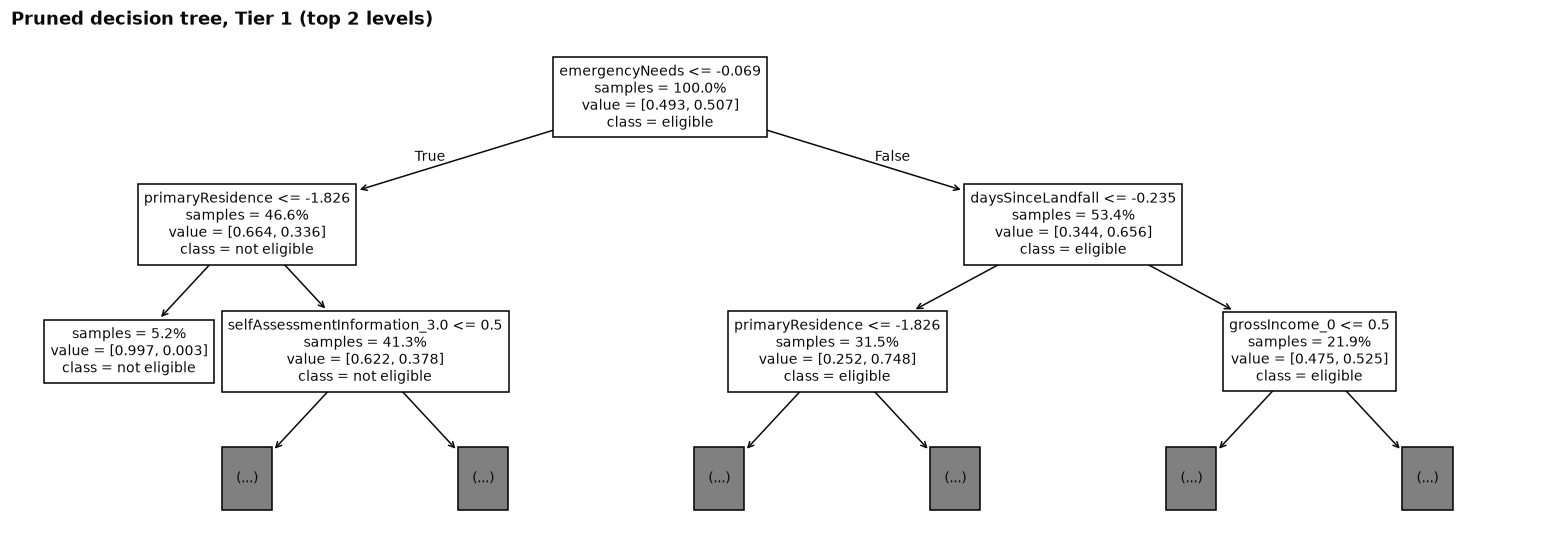

Total leaves in the pruned Tier 1 tree: 253


In [20]:
# Show the top 2 levels of the pruned Tier 1 tree, so we can read its first questions.
# The cut-off values are on the scaled (standardized) features: for a Yes/No column, "<= cut-off" means "No".
tree_pipe = FITTED[("Decision tree", "application")]
feature_names = [n.split("__", 1)[1] for n in tree_pipe.named_steps["prep"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(tree_pipe.named_steps["model"], max_depth=2, filled=False, impurity=False, proportion=True,
          class_names=["not eligible", "eligible"], feature_names=feature_names, fontsize=9, ax=ax)
ax.set_title("Pruned decision tree, Tier 1 (top 2 levels)")
save_fig("decision_tree_tier1")
plt.show()
print("Total leaves in the pruned Tier 1 tree:", tree_pipe.named_steps["model"].get_n_leaves())

### 📝 Analysis (Model 5)

Pruning made a huge difference, just like in Assignment 3. The unpruned tree (`ccp_alpha` = 0) had a cross-validated AUC of only 0.722 on Tier 1 and 0.808 on Tier 2, because it memorized the training rows.
With `ccp_alpha` = 0.00005 the CV AUC jumps to 0.865 and 0.929. The pruned tree scores almost the same on training and validation (0.869 vs. 0.864 on Tier 1), so it is no longer overfitting.

The pruned tree still has 253 leaves, too many to read in full, but its first questions make sense (chart above). The first split is whether the applicant reported **emergency needs**: those who did were eligible 66% of the time, those who did not only 34%.
Next it asks whether the home is the applicant's **primary residence**, and almost nobody whose home is not their primary residence was eligible. This matches FEMA's own rule that IHP only covers a primary home.
It also asks **how soon they applied** (`daysSinceLandfall`), with earlier applicants more likely to be eligible. A single readable tree reaching 0.864 on Tier 1 and 0.931 on Tier 2 is a strong result.

## Model 6: Random Forest

**What it is:** Builds many decision trees, each on a random sample of rows and a random subset of features, and lets them vote.

**Why we tried it:** A single tree changes a lot with small changes in the data. Averaging many trees fixes that and usually scores much higher. From Assignment 3.

**What we tuned:** `max_features` (how many features each split may look at) and `min_samples_leaf` (the smallest group a leaf may hold; larger = smoother trees). We use 200 trees.

In [21]:
name = "Random forest"
run_model(name, RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE),
          {"model__max_features": ["sqrt", 0.3], "model__min_samples_leaf": [1, 5]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,"max_features=0.3, min_samples_leaf=5",0.877,0.962,0.876,0.808,0.873,0.742,0.822,1.162
inspection,"max_features=0.3, min_samples_leaf=5",0.935,0.987,0.936,0.870,0.952,0.786,0.882,1.533


In [22]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,max_features,min_samples_leaf,CV AUC application,std application,CV AUC inspection,std inspection
0,sqrt,1,0.8693,0.0019,0.9304,0.0017
1,sqrt,5,0.8754,0.0015,0.9314,0.0017
2,0.3,1,0.8710,0.0017,0.9328,0.0018
3,0.3,5,0.8768,0.0014,0.9354,0.0016


### 📝 Analysis (Model 6)

The random forest is one of the strongest models: a validation AUC of 0.876 on Tier 1 and 0.936 on Tier 2. The same settings won on both tiers: `max_features` = 0.3 and `min_samples_leaf` = 5. Larger leaves helped because they keep each tree from chasing single applicants.

It has the biggest gap between training and validation of any model (0.962 vs. 0.876 on Tier 1). Each tree still memorizes a lot of its training rows.
But the validation score is as good as the cross-validated one (0.877), so averaging 200 trees keeps the forest from overfitting where it counts, on new applicants. It was also the slowest model to tune, at about 1.2 to 1.5 minutes per tier.

## Model 7: Gradient Boosting

**What it is:** Also builds many small trees, but one after another: each new tree focuses on the applicants the previous trees got wrong.

**Why we tried it:** It is usually the strongest model on tables like ours and handles interactions between features. In Assignment 3 we used `GradientBoostingClassifier`; here we use scikit-learn's `HistGradientBoostingClassifier`, the same idea but much faster on 116,000 rows (it groups each feature's values into bins first).

**What we tuned:** `learning_rate` (how big a step each new tree takes) and `max_leaf_nodes` (how complex each tree can be). The number of trees is chosen automatically with *early stopping*: training stops when an internal 10% hold-out stops improving.

In [23]:
name = "Gradient boosting"
run_model(name, HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
          {"model__learning_rate": [0.05, 0.1, 0.2], "model__max_leaf_nodes": [31, 63]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,"learning_rate=0.1, max_leaf_nodes=63",0.880,0.908,0.880,0.810,0.874,0.744,0.824,0.302
inspection,"learning_rate=0.05, max_leaf_nodes=63",0.937,0.948,0.938,0.871,0.955,0.784,0.882,0.497


In [24]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,learning_rate,max_leaf_nodes,CV AUC application,std application,CV AUC inspection,std inspection
0,0.05,31,0.8798,0.0016,0.9361,0.0015
1,0.05,63,0.8804,0.0013,0.9370,0.0014
2,0.10,31,0.8797,0.0015,0.9357,0.0016
3,0.10,63,0.8805,0.0014,0.9367,0.0015
4,0.20,31,0.8789,0.0012,0.9349,0.0016
5,0.20,63,0.8791,0.0014,0.9362,0.0013


### 📝 Analysis (Model 7)

Gradient boosting is the best model on both tiers: a validation AUC of 0.880 on Tier 1 and 0.938 on Tier 2, with accuracies of 0.810 and 0.871.
Its training and validation scores are close (0.908 vs. 0.880 on Tier 1, 0.948 vs. 0.938 on Tier 2), so early stopping kept it from overfitting.

The settings barely mattered. All six combinations were within 0.002 of each other on Tier 1 (CV AUC 0.8789 to 0.8805), and the untuned baseline from our project code already scored 0.880 and 0.938.
So for this data, the type of model makes a big difference and the fine-tuning makes very little. It is also fast, at under half a minute per tier.

## Model 8: Neural Network (MLP)

**What it is:** Layers of small units that each combine the inputs and pass the result on. It can learn curved boundaries and interactions.

**Why we tried it:** From Assignment 4. It is a flexible "black box" model, and tells us whether more flexibility beats the tree models.

**What we tuned:** `hidden_layer_sizes` (how many units and layers) and `alpha` (regularization, like `C` in logistic regression). We use *early stopping* so training stops before the network memorizes the training rows. To save time we **tune on a stratified sample of 40,000 training rows**, then refit the best settings on all training rows.

In [25]:
name = "Neural network"
run_model(name, MLPClassifier(max_iter=200, early_stopping=True, random_state=RANDOM_STATE),
          {"model__hidden_layer_sizes": [(32,), (64,), (64, 32)], "model__alpha": [0.0001, 0.01]},
          tune_rows=40_000)

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,"alpha=0.0001, hidden_layer_sizes=(64, 32)",0.867,0.882,0.874,0.805,0.872,0.736,0.819,0.110
inspection,"alpha=0.0001, hidden_layer_sizes=(64, 32)",0.929,0.941,0.934,0.865,0.947,0.781,0.877,0.131


In [26]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,alpha,hidden_layer_sizes,CV AUC application,std application,CV AUC inspection,std inspection
0,0.0001,"(32,)",0.8644,0.0035,0.9265,0.0032
1,0.0001,"(64,)",0.8651,0.0051,0.9256,0.0037
2,0.0001,"(64, 32)",0.8665,0.0040,0.9287,0.0049
3,0.0100,"(32,)",0.8653,0.0041,0.9269,0.0029
4,0.0100,"(64,)",0.8652,0.0052,0.9260,0.0045
5,0.0100,"(64, 32)",0.8662,0.0048,0.9285,0.0043


### 📝 Analysis (Model 8)

The neural network came in third: a validation AUC of 0.874 on Tier 1 and 0.934 on Tier 2. It sits right next to the random forest and just behind gradient boosting.
The two-layer network (64 then 32 units) with light regularization was best on both tiers. The training and validation scores are very close (0.882 vs. 0.874 on Tier 1), so early stopping did its job.

As with KNN, the validation AUC is a bit higher than the cross-validated one, because tuning used a 40,000-row sample and the final network trained on all rows.
The network is flexible but does not beat gradient boosting, and it is much harder to explain. For a "black box" model to be worth it, it would need to do clearly better, and here it does not.

## Model 9: Linear Support Vector Machine

**What it is:** Finds the straight boundary with the widest possible gap (margin) between the two classes.

**Why we tried it:** From Assignment 4. In Assignment 4 we used `SVC(kernel="linear")`, but that is far too slow for 116,000 rows, so we use `LinearSVC`, which gives the same kind of model much faster. It has no probabilities, so its AUC is computed from its distance to the boundary.

**What we tuned:** `C`, the trade-off between a wide margin and classifying every training row correctly.

In [27]:
name = "Linear SVM"
run_model(name, LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
          {"model__C": [0.001, 0.01, 0.1, 1]})

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,C=0.1,0.818,0.815,0.820,0.753,0.791,0.714,0.765,0.102
inspection,C=0.1,0.897,0.897,0.899,0.820,0.852,0.786,0.827,0.183


In [28]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,C,CV AUC application,std application,CV AUC inspection,std inspection
0,0.001,0.8173,0.0021,0.8966,0.0010
1,0.010,0.8177,0.0021,0.8971,0.0009
2,0.100,0.8177,0.0021,0.8971,0.0009
3,1.000,0.8177,0.0021,0.8971,0.0009


### 📝 Analysis (Model 9)

The linear SVM matches logistic regression almost exactly: a validation AUC of 0.820 on Tier 1 and 0.899 on Tier 2. Every value of `C` gave nearly the same score.
This is expected, since both models draw a straight boundary and differ only in how they place it. The training and validation scores are the same, so there is no overfitting.

Its sensitivity (0.791) and specificity (0.714) on Tier 1 are also almost identical to logistic regression. Four different straight-line models (logistic regression, LDA, linear SVM, and regularized QDA) all landed between 0.816 and 0.822 on Tier 1.
That is strong evidence that 0.82 is the ceiling for a straight-line boundary on this data.

## Model 10: RBF-Kernel Support Vector Machine

**What it is:** An SVM that can draw curved boundaries by measuring how close applicants are to each other (the RBF kernel).

**Why we tried it:** From Assignment 4. It tests whether a curved SVM boundary helps. Its training time grows roughly with the *square* of the number of rows, so it cannot run on all 116,000. We **tune and fit it on a stratified sample of 15,000 training rows** and score it on the full validation set like every other model.

**What we tuned:** `C` (as in the linear SVM) and `gamma` (how far each training row's influence reaches; larger = a more wiggly boundary).

In [29]:
name = "RBF SVM"
run_model(name, SVC(kernel="rbf", random_state=RANDOM_STATE),
          {"model__C": [1, 10], "model__gamma": ["scale", 0.01]}, tune_rows=15_000, final_rows=15_000)

,best settings,CV AUC,train AUC,val AUC,val accuracy,val sensitivity,val specificity,val F1,minutes
tier,,,,,,,,,
application,"C=1, gamma=scale",0.855,0.893,0.855,0.793,0.875,0.708,0.811,0.231
inspection,"C=10, gamma=0.01",0.916,0.948,0.918,0.855,0.945,0.762,0.869,0.289


In [30]:
show_cv(name)  # every setting tried, mean AUC over the 5 folds

,C,gamma,CV AUC application,std application,CV AUC inspection,std inspection
0,1,scale,0.8548,0.0064,0.9131,0.0032
1,1,0.01,0.8509,0.0083,0.9109,0.0025
2,10,scale,0.8435,0.0079,0.9102,0.0040
3,10,0.01,0.8548,0.0061,0.9159,0.0032


### 📝 Analysis (Model 10)

The RBF SVM clearly beats the linear SVM (0.855 vs. 0.820 on Tier 1, 0.918 vs. 0.899 on Tier 2), so letting the boundary curve helps.
It still ranks behind the tree models and the neural network, though. One reason is that it only learned from a 15,000-row sample, about an eighth of the training rows every other model used.

It also shows some overfitting (training AUC 0.893 vs. validation 0.855 on Tier 1). The best settings differed between tiers (C=1 with the default gamma on Tier 1, C=10 with gamma=0.01 on Tier 2).
Even if we could train it on all rows, the tree models are already better and much faster, so the RBF SVM is not a practical choice at this data size.

---
# Part 3: Model Comparison

## All models side by side
Sorted by validation AUC within each tier. **Gap** = training AUC minus validation AUC; a large gap means overfitting.

In [31]:
results = pd.DataFrame(RESULTS)
results["gap"] = results["train AUC"] - results["val AUC"]
summary_cols = ["CV AUC", "train AUC", "val AUC", "gap", "val accuracy", "val sensitivity",
                "val specificity", "val F1", "minutes", "best settings"]
for tier in TIERS:
    print(TIER_NAMES[tier])
    display(results[results.tier == tier].set_index("model")[summary_cols]
            .sort_values("val AUC", ascending=False).round(3))

Tier 1 (application)


,CV AUC,train AUC,val AUC,gap,val accuracy,val sensitivity,val specificity,val F1,minutes,best settings
model,,,,,,,,,,
Gradient boosting,0.880,0.908,0.880,0.028,0.810,0.874,0.744,0.824,0.302,"learning_rate=0.1, max_leaf_nodes=63"
Random forest,0.877,0.962,0.876,0.086,0.808,0.873,0.742,0.822,1.162,"max_features=0.3, min_samples_leaf=5"
Neural network,0.867,0.882,0.874,0.007,0.805,0.872,0.736,0.819,0.110,"alpha=0.0001, hidden_layer_sizes=(64, 32)"
Decision tree,0.865,0.869,0.864,0.005,0.799,0.869,0.728,0.814,0.099,ccp_alpha=5e-05
RBF SVM,0.855,0.893,0.855,0.039,0.793,0.875,0.708,0.811,0.231,"C=1, gamma=scale"
KNN,0.832,0.871,0.851,0.019,0.784,0.845,0.722,0.799,0.030,n_neighbors=31
QDA,0.823,0.823,0.822,0.001,0.762,0.864,0.657,0.786,0.053,reg_param=0.1
Logistic regression,0.818,0.816,0.820,-0.004,0.754,0.790,0.717,0.765,0.056,C=10
Linear SVM,0.818,0.815,0.820,-0.004,0.753,0.791,0.714,0.765,0.102,C=0.1


Tier 2 (inspection)


,CV AUC,train AUC,val AUC,gap,val accuracy,val sensitivity,val specificity,val F1,minutes,best settings
model,,,,,,,,,,
Gradient boosting,0.937,0.948,0.938,0.010,0.871,0.955,0.784,0.882,0.497,"learning_rate=0.05, max_leaf_nodes=63"
Random forest,0.935,0.987,0.936,0.051,0.870,0.952,0.786,0.882,1.533,"max_features=0.3, min_samples_leaf=5"
Neural network,0.929,0.941,0.934,0.007,0.865,0.947,0.781,0.877,0.131,"alpha=0.0001, hidden_layer_sizes=(64, 32)"
Decision tree,0.929,0.933,0.931,0.002,0.865,0.951,0.777,0.878,0.120,ccp_alpha=5e-05
RBF SVM,0.916,0.948,0.918,0.030,0.855,0.945,0.762,0.869,0.289,"C=10, gamma=0.01"
KNN,0.900,0.926,0.913,0.013,0.837,0.907,0.765,0.850,0.019,n_neighbors=31
Logistic regression,0.898,0.898,0.900,-0.002,0.821,0.852,0.790,0.829,0.083,C=10
Linear SVM,0.897,0.897,0.899,-0.002,0.820,0.852,0.786,0.827,0.183,C=0.1
QDA,0.893,0.895,0.894,0.001,0.714,0.505,0.929,0.641,0.094,reg_param=0.1


## Validation AUC by model

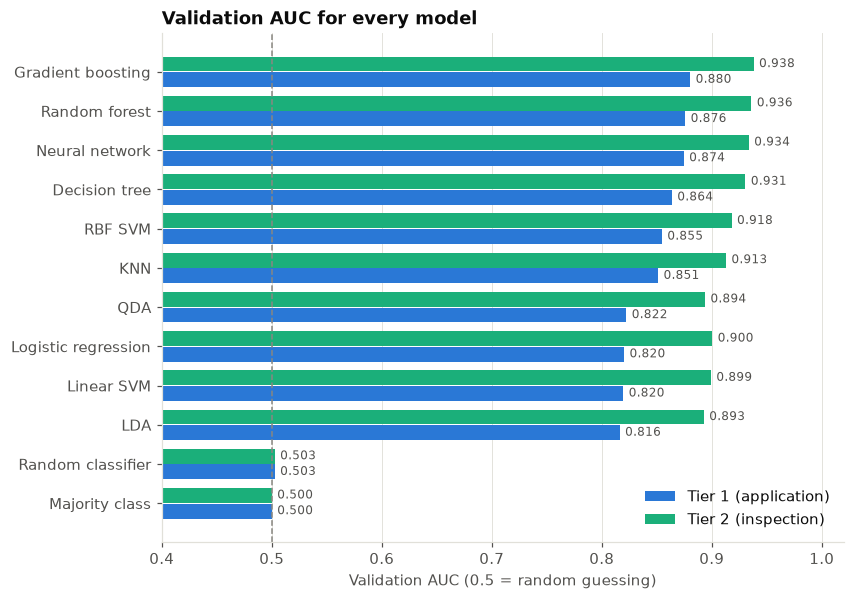

In [32]:
order = (results[results.tier == "application"].set_index("model")["val AUC"].sort_values().index)
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(order))
h = 0.38
for i, tier in enumerate(TIERS):
    vals = results[results.tier == tier].set_index("model").loc[order, "val AUC"]
    bars = ax.barh(y + (i - 0.5) * (h + 0.02), vals, height=h, color=TIER_COLORS[tier], label=TIER_NAMES[tier])
    for b, v in zip(bars, vals):
        ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=8, color=INK_SOFT)
ax.set_yticks(y, order)
ax.set_xlim(0.4, 1.02)
ax.axvline(0.5, color=GRAY, lw=1, ls="--")
ax.set_xlabel("Validation AUC (0.5 = random guessing)")
ax.set_title("Validation AUC for every model")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig("val_auc_by_model")
plt.show()

## ROC curves on the validation set
Each curve shows the trade-off between catching eligible applicants (sensitivity, up) and wrongly flagging ineligible ones (1 - specificity, right).
The closer a curve hugs the top-left corner, the better. The best model in each tier is highlighted; the other models are gray.

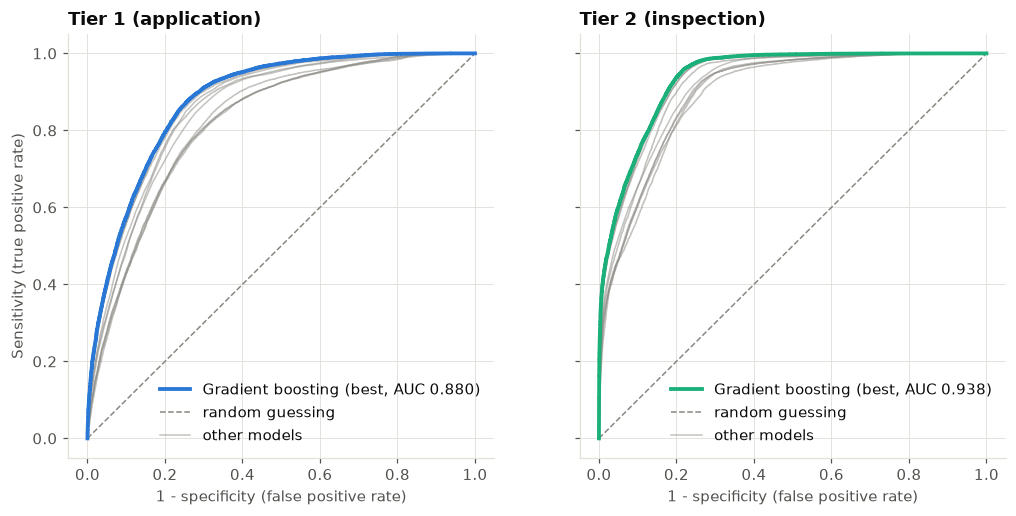

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, tier in zip(axes, TIERS):
    X_va, y_va = DATA[tier]["val"]
    tier_res = results[(results.tier == tier) & ~results.model.isin(["Random classifier", "Majority class"])]
    best_name = tier_res.sort_values("val AUC").model.iloc[-1]
    for name in tier_res.model:
        fpr, tpr, _ = roc_curve(y_va, model_scores(FITTED[(name, tier)], X_va))
        is_best = name == best_name
        ax.plot(fpr, tpr, color=TIER_COLORS[tier] if is_best else GRAY, lw=2.5 if is_best else 1,
                alpha=1 if is_best else 0.5, zorder=3 if is_best else 2,
                label=f"{name} (best, AUC {tier_res.set_index('model').loc[name, 'val AUC']:.3f})" if is_best else None)
    ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="random guessing")
    ax.plot([], [], color=GRAY, lw=1, alpha=0.5, label="other models")
    ax.set_title(TIER_NAMES[tier])
    ax.set_xlabel("1 - specificity (false positive rate)")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Sensitivity (true positive rate)")
save_fig("roc_curves_validation")
plt.show()

## Overfitting check: training vs. validation AUC

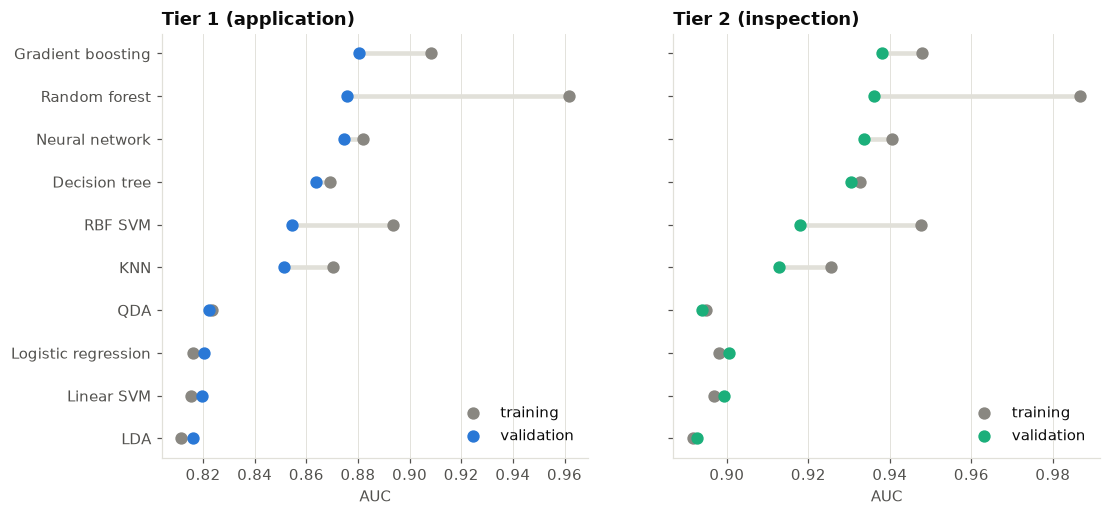

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, tier in zip(axes, TIERS):
    r = results[(results.tier == tier) & ~results.model.isin(["Random classifier", "Majority class"])]
    r = r.set_index("model").loc[[m for m in order if m in r.model.values]]
    yy = np.arange(len(r))
    ax.hlines(yy, r["val AUC"], r["train AUC"], color=GRID, lw=3, zorder=1)
    ax.scatter(r["train AUC"], yy, s=50, color=GRAY, zorder=2, label="training")
    ax.scatter(r["val AUC"], yy, s=50, color=TIER_COLORS[tier], zorder=3, label="validation")
    ax.set_yticks(yy, r.index)
    ax.set_title(TIER_NAMES[tier])
    ax.set_xlabel("AUC")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
save_fig("train_vs_val_auc")
plt.show()

## Confusion matrices of the best model (validation set)

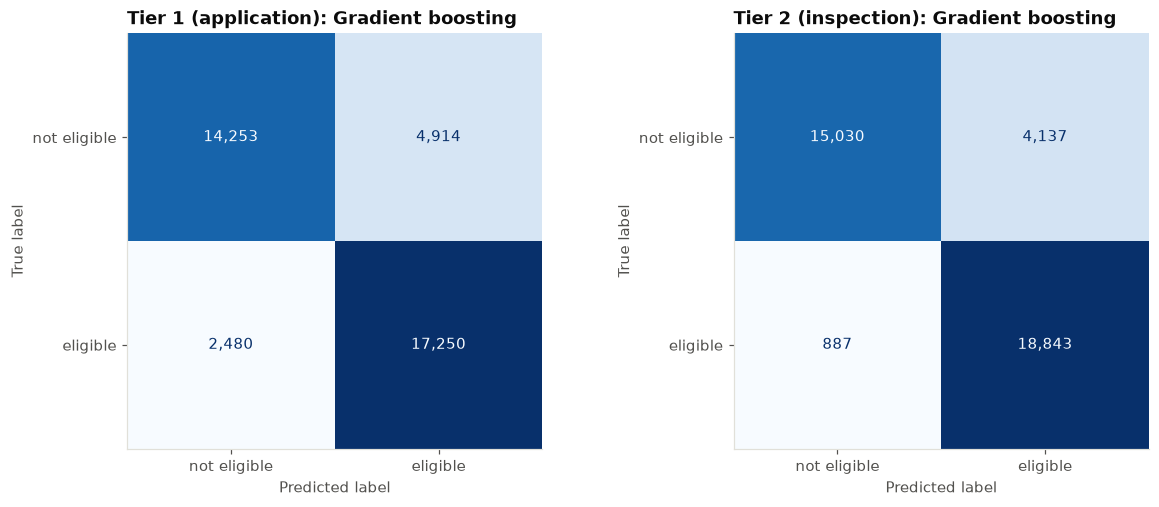

{'application': 'Gradient boosting', 'inspection': 'Gradient boosting'}

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
BEST = {}
for ax, tier in zip(axes, TIERS):
    r = results[results.tier == tier].sort_values("val AUC")
    BEST[tier] = r.model.iloc[-1]
    X_va, y_va = DATA[tier]["val"]
    ConfusionMatrixDisplay.from_estimator(FITTED[(BEST[tier], tier)], X_va, y_va, ax=ax, colorbar=False,
                                          display_labels=["not eligible", "eligible"], cmap="Blues",
                                          values_format=",d")
    ax.set_title(f"{TIER_NAMES[tier]}: {BEST[tier]}")
    ax.grid(False)
save_fig("confusion_matrix_best_validation")
plt.show()
BEST

### 📝 Analysis (Model comparison and selection)

**The models fall into three groups.**
1. **Straight-line models** (logistic regression, LDA, linear SVM, QDA): about 0.82 AUC on Tier 1 and 0.89 to 0.90 on Tier 2. Four different methods hitting the same ceiling tells us a straight boundary is not enough.
2. **Flexible distance-based models** (KNN, RBF SVM): 0.851 to 0.855 on Tier 1 and 0.913 to 0.918 on Tier 2.
3. **Tree models and the neural network**: 0.864 to 0.880 on Tier 1 and 0.931 to 0.938 on Tier 2. Eligibility depends on *combinations* of answers (for example, primary residence **and** emergency needs), and trees capture rule-like combinations well. That fits how FEMA's process works.

**The inspection features matter.** The best model goes from 0.880 on Tier 1 to 0.938 on Tier 2. Tier 1 is the more useful case for triaging applications the day they arrive, and it still gets well above the 0.50 baseline using only what people report when they register.

**Our choice: gradient boosting, for both tiers.** It has the highest validation AUC on both tiers, a small training/validation gap (0.028 and 0.010), and it is fast.
The top four models are close, though (within 0.016 on Tier 1 and 0.007 on Tier 2). The **pruned decision tree** is worth keeping as a runner-up: it gives up a little accuracy but can be read and explained to non-technical people.
We also keep **logistic regression** as the simple reference model in the final test.

**The errors lean one way.** On Tier 1, gradient boosting caught 17,250 of the 19,730 eligible applicants (it missed 2,480), but it also predicted "eligible" for 4,914 of the 19,167 people who were not.
On Tier 2 it missed only 887 eligible applicants, while 4,137 ineligible people were predicted eligible. So the model is better at not missing eligible people than at spotting ineligible ones.
If missing an eligible family is worse than a false alarm, that is the right direction. The team can move the decision cut-off to change this balance.

**Tuning helped less than choosing the right type of model.** The tuned gradient boosting scores the same as the untuned baseline (0.880 and 0.938). For most models, the different settings in each grid were within a few thousandths of each other.
The exceptions were the decision tree (pruning was essential) and KNN (K had to be large enough).

---
# Part 4: Final Test

The test set has been locked since the split. It is used **once**, after the team has frozen the model choice, to get an honest score on applicants no model has ever seen.
Until then, `RUN_FINAL_TEST` stays `False` so nobody looks at the test scores while still making choices.

In [36]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    rows = []
    for tier in TIERS:
        X_te, y_te = DATA[tier]["test"]
        for name in ["Logistic regression", BEST[tier]]:
            rows.append({"tier": TIER_NAMES[tier], "model": name, **evaluate(FITTED[(name, tier)], X_te, y_te)})
    display(pd.DataFrame(rows).set_index(["tier", "model"]).round(3))
else:
    print("Test set still locked. Set RUN_FINAL_TEST = True after the model freeze.")

Test set still locked. Set RUN_FINAL_TEST = True after the model freeze.


### 📝 Analysis (Final test)

To be written after the model freeze, once the test scores are run.